
# 1. Introduction

## 1.1 Project Overview

Airbnb is an online platform that allows people to rent accommodation such as apartments, private rooms and shared rooms.

This project focuses on analysing the New York City Airbnb Open Data dataset, which contains information about Airbnb listings in New York City during 2019.

The dataset includes information about listing prices, room types, neighbourhoods, hosts, customer reviews and availability.

The project involves data understanding, preprocessing, exploratory data analysis and data visualization to identify useful patterns and insights from the dataset.

## 1.2 Problem Statement

The Airbnb dataset contains information about thousands of listings across New York City. Understanding this information can help identify differences in listing prices, room types, neighbourhoods and availability.

The main problem is to examine the dataset, identify data quality issues, and analyse the information to discover meaningful patterns and relationships.

## 1.3 Project Objectives

1. To understand the structure and characteristics of the dataset.
2. To identify and handle missing values and duplicate records.
3. To examine data types and detect unusual values.
4. To perform exploratory data analysis using statistical methods.
5. To investigate relationships between different attributes.
6. To create visualizations that communicate important findings.

## 1.4 Project Scope

This project focuses on data preprocessing, exploratory data analysis and data visualization of New York City Airbnb listings.

The analysis will use Python and the Pandas, NumPy, Matplotlib and Seaborn libraries.

Machine learning and predictive model development are outside the scope of this project.



# 2. Dataset Description

## 2.1 Dataset Information

**Dataset Name:** New York City Airbnb Open Data (2019)

**Dataset Source:** Kaggle

**Dataset Link:** https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data

**File Name:** AB_NYC_2019.csv

**File Format:** CSV (Comma-Separated Values)

**Target Variable:** Not applicable, as this project focuses on data preprocessing, exploratory data analysis and visualization rather than prediction.

**Brief Description:**

The dataset contains information about Airbnb listings in New York City during 2019. It includes listing details, host information, geographical locations, room types, prices, customer reviews and availability.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/AB_NYC_2019.csv")

BASIC DATASET INSPECTION

In [2]:
df.shape

(48895, 16)


### Dataset Dimensions

The dataset contains 48,895 records and 16 attributes. Each record represents an Airbnb listing in New York City, while the attributes provide information about the listing, host, location, price, reviews and availability.


In [16]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')


## 2.2 Dataset Attributes

The dataset contains the following 16 attributes:

id | Unique identification number of the listing 
name | Name or title of the Airbnb listing 
host_id | Unique identification number of the host 
host_name | Name of the host 
neighbourhood_group | Borough or major area of New York City
neighbourhood | Specific neighbourhood of the listing 
latitude | Geographic latitude of the listing 
longitude | Geographic longitude of the listing 
room_type | Type of accommodation offered 
price | Price of the listing per night 
minimum_nights | Minimum number of nights required for booking 
number_of_reviews | Total number of reviews received 
last_review | Date of the most recent review 
reviews_per_month | Average number of reviews per month
calculated_host_listings_count | Number of listings associated with the host 
availability_365 | Number of days the listing is available during the year 


In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



### 2.3 Initial Dataset Overview

The first five records show that the dataset contains information about Airbnb listings, hosts, locations, room types, prices, reviews and availability.

The records show variations in listing prices, minimum nights and room types. Some missing values are also visible in the review-related columns, indicating the need for further data quality assessment during preprocessing.


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n


### 2.4 Initial Data Structure and Data Types

After checking the dataset, I found that it contains 48,895 records and 16 columns. The columns store different types of information, such as listing details, host information, location, price and reviews.

The dataset contains 7 integer columns, 3 floating-point columns and 6 string columns.

During this inspection, I also noticed that some values are missing in the `name`, `host_name`, `last_review` and `reviews_per_month` columns. These missing values will be examined and handled during the data preprocessing stage.



In [20]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


### Missing Value Inspection

After checking for missing values, I found that four columns contain empty entries. The `name` column has 16 missing values, while `host_name` has 21. The `last_review` and `reviews_per_month` columns have 10,052 missing values each.

The remaining columns do not contain any missing values. These results will help us decide how to handle the missing data during preprocessing.


In [4]:
df.duplicated().sum()

np.int64(0)


### Duplicate Records Inspection

After checking the dataset for duplicate records, I found that there are no completely duplicated rows. All 48,895 records are unique based on the columns present in the dataset. Therefore, no duplicate records need to be removed.


In [5]:
df['room_type'].value_counts()

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


### Room Type Distribution

The dataset contains three types of rooms: Entire home/apt, Private room and Shared room. Entire homes and apartments have the highest number of listings, with 25,409 records, followed by private rooms with 22,326 records. Shared rooms have the lowest number of listings, with only 1,160 records.

This shows that most Airbnb listings in the dataset offer either an entire home or a private room.


In [6]:
df['neighbourhood_group'].value_counts()

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64


### Neighbourhood Group Distribution

From the results, I noticed that most of the Airbnb listings are located in Manhattan and Brooklyn. Manhattan has 21,661 listings, while Brooklyn has 20,104. Queens has 5,666 listings, and the number is much lower in the Bronx and Staten Island. This shows that most of the listings in the dataset are concentrated in Manhattan and Brooklyn.


In [8]:
(df.isnull().sum() / len(df)) * 100

id                                 0.000000
name                               0.032723
host_id                            0.000000
host_name                          0.042949
neighbourhood_group                0.000000
neighbourhood                      0.000000
latitude                           0.000000
longitude                          0.000000
room_type                          0.000000
price                              0.000000
minimum_nights                     0.000000
number_of_reviews                  0.000000
last_review                       20.558339
reviews_per_month                 20.558339
calculated_host_listings_count     0.000000
availability_365                   0.000000
dtype: float64


### Checking Listings with No Reviews

Before handling the missing values in `last_review` and `reviews_per_month`, I want to check how many listings have not received any reviews. This will help me understand whether the missing review information is related to listings with no reviews.


In [9]:
(df['number_of_reviews'] == 0).sum()

np.int64(10052)


The result shows that 10,052 listings have not received any reviews. This is the same number of missing values found in the `last_review` and `reviews_per_month` columns. This suggests that these values are missing because those listings have not received any reviews.


In [10]:
df.loc[df['number_of_reviews'] == 0, ['last_review', 'reviews_per_month']].isnull().all()

last_review          True
reviews_per_month    True
dtype: bool


The output shows True for both columns. This means that whenever the number of reviews is zero, the last review date and reviews per month are also missing. Since these listings have no reviews, there is no need to fill these values with anything.


In [7]:
df_clean = df.copy()

In [8]:
df_clean['name'] = df_clean['name'].fillna('Unknown')
df_clean['host_name'] = df_clean['host_name'].fillna('Unknown')


After filling the missing values in the name and host_name columns with 'Unknown', I checked the dataset again to see whether the changes were applied correctly.


In [9]:
df_clean.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


After making these changes, I checked the missing values again. The missing values in name and host_name have been removed successfully. However, last_review and reviews_per_month still contain 10,052 missing values each. I have kept these values unchanged because the corresponding listings have not received any reviews.


In [10]:
df_clean.duplicated().sum()

np.int64(0)


I checked the cleaned dataset for duplicate records and found that there are none. So, there is no need to remove any rows due to duplication.


In [11]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48895 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48895 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n


While checking the data types, I noticed that the last_review column is stored as a string even though it contains dates. I will convert it into a datetime format so that it can be used properly for date-related analysis.


In [17]:
df_clean['last_review'] = pd.to_datetime(df_clean['last_review'])
df_clean['last_review'].dtype

dtype('<M8[us]')


The last_review column was previously stored as a string. I converted it into datetime format successfully. Now the column can be used for date-related operations and analysis.

CHECK OUTLIERS

In [19]:
df_clean['price'].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


While checking the price column, I noticed that the average price is 152.72, whereas the median is 106. The maximum price is 10,000, which is much higher than most of the values. I also found that the minimum price is zero. These values need further checking before deciding whether any changes are required.

In [20]:
Q1 = df_clean['price'].quantile(0.25)
Q3 = df_clean['price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: -90.0
Upper limit: 334.0



Using the IQR method, I calculated the lower and upper limits for the price column. The lower limit is -90 and the upper limit is 334. This means that prices above 334 can be considered potential outliers. I will examine these values further before deciding whether to remove or keep them.

In [21]:
((df_clean['price'] < lower_limit) | (df_clean['price'] > upper_limit)).sum()

np.int64(2972)


After applying the IQR method, I found 2,972 potential outliers in the price column. These are listings with prices above 334. However, a higher price does not always mean that the data is incorrect, so I will examine these records before deciding what to do with them.

In [22]:
(df_clean['price'] == 0).sum()

np.int64(11)


I also checked the listings with a price of zero and found 11 such records. Since a listing price of zero seems unusual, I will examine these records before deciding how to handle them.

In [23]:
df_clean[df_clean['price'] == 0]

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",8993084,Kimberly,Brooklyn,Bedford-Stuyvesant,40.69023,-73.95428,Private room,0,4,1,2018-01-06,0.05,4,28
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,131697576,Anisha,Bronx,East Morrisania,40.83296,-73.88668,Private room,0,2,55,2019-06-24,2.56,4,127
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",15787004,Martial Loft,Brooklyn,Bushwick,40.69467,-73.92433,Private room,0,2,16,2019-05-18,0.71,5,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",1641537,Lauren,Brooklyn,Greenpoint,40.72462,-73.94072,Private room,0,2,12,2017-10-27,0.53,2,0
25778,20624541,Modern apartment in the heart of Williamsburg,10132166,Aymeric,Brooklyn,Williamsburg,40.70838,-73.94645,Entire home/apt,0,5,3,2018-01-02,0.15,1,73
25794,20639628,Spacious comfortable master bedroom with nice ...,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68173,-73.91342,Private room,0,1,93,2019-06-15,4.28,6,176
25795,20639792,Contemporary bedroom in brownstone with nice view,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68279,-73.91170,Private room,0,1,95,2019-06-21,4.37,6,232
25796,20639914,Cozy yet spacious private brownstone bedroom,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68258,-73.91284,Private room,0,1,95,2019-06-23,4.35,6,222
26259,20933849,the best you can find,13709292,Qiuchi,Manhattan,Murray Hill,40.75091,-73.97597,Entire home/apt,0,3,0,NaT,NaN,1,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,101970559,Sergii,Brooklyn,Bushwick,40.69211,-73.90670,Shared room,0,30,2,2019-06-22,0.11,6,333



While checking the records with zero prices, I noticed that these listings contain other information, such as host details, room types and reviews. However, a price of zero is not suitable for our price analysis. So, I decided to remove these 11 records from the cleaned dataset.

In [27]:
df_clean = df_clean[df_clean['price'] > 0]
(df_clean['price'] == 0).sum()

np.int64(0)

In [29]:
(df_clean['price'] > upper_limit).sum()

np.int64(2972)


After checking the upper price limit, I found 2,972 listings with prices above 334. These values are considered potential outliers according to the IQR method. However, some Airbnb properties may naturally have higher prices, so I decided to keep these records instead of removing them without further evidence.

In [30]:
df_clean['price'].nlargest(10)

9151     10000
17692    10000
29238    10000
6530      9999
12342     9999
40433     9999
30268     8500
4377      8000
29662     7703
42523     7500
Name: price, dtype: int64


I checked the 10 highest prices in the dataset and found that some listings have prices as high as 10,000 per night. These values are much higher than the average price, but they may represent expensive properties. Since I cannot confirm that these prices are incorrect, I decided to keep them in the dataset and consider them during the analysis.

In [31]:
df_clean.shape

(48884, 16)


After completing the initial cleaning steps, the dataset now contains 48,884 records and 16 columns. I removed the 11 listings with zero prices and kept the high-priced listings because they may represent genuine properties. The original dataset has been left unchanged.

In [12]:
df_clean.to_csv("../data/processed/AB_NYC_2019_cleaned.csv", index=False)

In [33]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (48895, 16)
Cleaned dataset: (48884, 16)



After comparing the original and cleaned datasets, I found that the number of records decreased from 48,895 to 48,884. This happened because I removed 11 listings with zero prices. The number of columns remains the same. The other changes, such as filling missing names and converting the review date column, have also been applied.

In [34]:
df_clean.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.888400e+04,4.888400e+04,48884.000000,48884.000000,48884.000000,48884.000000,48884.000000,38833,38833.000000,48884.000000,48884.000000
mean,1.901679e+07,6.762203e+07,40.728953,-73.952176,152.755053,7.029887,23.271991,2018-10-04 01:15:09.896222,1.373128,7.144628,112.779498
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,10.000000,1.000000,0.000000,2011-03-28 00:00:00,0.010000,1.000000,0.000000
25%,9.470548e+06,7.817310e+06,40.690100,-73.983080,69.000000,1.000000,1.000000,2018-07-08 00:00:00,0.190000,1.000000,0.000000
50%,1.967574e+07,3.079257e+07,40.723080,-73.955685,106.000000,3.000000,5.000000,2019-05-19 00:00:00,0.720000,1.000000,45.000000
75%,2.915297e+07,1.074344e+08,40.763120,-73.936290,175.000000,5.000000,24.000000,2019-06-23 00:00:00,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,2019-07-08 00:00:00,58.500000,327.000000,365.000000
std,1.098432e+07,7.861666e+07,0.054532,0.046159,240.170260,20.512224,44.551331,NaN,1.680391,32.956185,131.627271



### Descriptive Statistics

After looking at the statistical summary, I noticed some differences between the average and median values. The average price is 152.76, while the median is 106. The average minimum nights is around 7, but the median is only 3. The number of reviews also varies a lot between listings. Some properties have received many reviews, while others have very few. Availability is also different for each listing, ranging from 0 to 365 days.

In [35]:
df_clean['price'].describe()

count    48884.000000
mean       152.755053
std        240.170260
min         10.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

The average price of the listings is $152.76, while the median price is $106. This difference shows that some expensive listings are increasing the average. Most listings have prices between $69 and $175, but a few listings have much higher prices. The standard deviation of $240.17 also indicates considerable variation in listing prices.

Categorical attribute analysis

In [36]:
df_clean['minimum_nights'].value_counts().head(10)

minimum_nights
1     12717
2     11693
3      7998
30     3758
4      3302
5      3033
7      2058
6       752
14      562
10      483
Name: count, dtype: int64

From the results, I found that most Airbnb listings allow guests to book for a minimum of 1, 2 or 3 nights. There are also 3,758 listings that require a minimum stay of 30 nights. This shows that minimum-stay requirements differ between properties. Some listings are suitable for short stays, while others require guests to stay for a longer period.

In [37]:
df_clean['number_of_reviews'].value_counts().head(10)

number_of_reviews
0    10051
1     5243
2     3464
3     2519
4     1994
5     1617
6     1357
7     1179
8     1127
9      964
Name: count, dtype: int64

From the results, I noticed that 10,051 listings have received no reviews. The number of listings decreases as the review count increases. For example, 5,243 listings have only one review, while 964 listings have nine reviews. This indicates that many properties have received few or no reviews, whereas only a smaller number have received a large number of reviews.

In [38]:
df_clean['room_type'].value_counts()

room_type
Entire home/apt    25407
Private room       22319
Shared room         1158
Name: count, dtype: int64

In [39]:
df_clean['room_type'].value_counts(normalize=True) * 100

room_type
Entire home/apt    51.974061
Private room       45.657066
Shared room         2.368873
Name: proportion, dtype: float64

After analysing the room types, I found that entire homes or apartments make up the largest category, with around 51.97% of all listings. Private rooms account for 45.66%, while shared rooms represent only 2.37%. This shows that most Airbnb properties in the dataset offer either an entire home or a private room.

In [41]:
df_clean['neighbourhood_group'].value_counts()


neighbourhood_group
Manhattan        21660
Brooklyn         20095
Queens            5666
Bronx             1090
Staten Island      373
Name: count, dtype: int64

In [13]:
df_clean['neighbourhood_group'].value_counts(normalize=True) * 100

neighbourhood_group
Manhattan        44.301053
Brooklyn         41.116679
Queens           11.588097
Bronx             2.231312
Staten Island     0.762859
Name: proportion, dtype: float64

After analysing the neighbourhood groups, I found that Manhattan has the highest number of Airbnb listings, accounting for around 44.31% of the dataset. Brooklyn comes next with 41.11%. Queens has a smaller share of 11.59%, while the Bronx and Staten Island have very few listings. This shows that Airbnb listings in the dataset are mainly concentrated in Manhattan and Brooklyn.

Relationship analysis
Now we will examine how room type is related to listing prices. This is our first meaningful relationship analysis.

In [14]:
df_clean.groupby('room_type')['price'].median()

room_type
Entire home/apt    160.0
Private room        70.0
Shared room         45.0
Name: price, dtype: float64

After comparing room types with their median prices, I found that entire homes or apartments have the highest median price of $160. Private rooms have a median price of $70, while shared rooms have the lowest median price of $45. This shows that the type of accommodation is related to its listing price, with entire homes and apartments generally costing more.

In [44]:
df_clean.groupby('neighbourhood_group')['price'].median()

neighbourhood_group
Bronx             65.0
Brooklyn          90.0
Manhattan        150.0
Queens            75.0
Staten Island     75.0
Name: price, dtype: float64

After comparing prices across neighbourhood groups, I found that Manhattan has the highest median listing price at $150. Brooklyn comes next at $90, followed by Queens and Staten Island, both at $75. The Bronx has the lowest median price at $65. This indicates that listing prices vary depending on the neighbourhood group, with Manhattan being the most expensive among the five groups.

In [45]:
df_clean.groupby('room_type')['availability_365'].median()

room_type
Entire home/apt    42.0
Private room       45.0
Shared room        90.0
Name: availability_365, dtype: float64

After comparing room types with their availability, I found that shared rooms have the highest median availability of 90 days. Private rooms have a median availability of 45 days, while entire homes or apartments have 42 days. This suggests that shared rooms are available for more days during the year compared with the other two room types.

Correlation analysis

In [46]:
df_clean[['price', 'minimum_nights', 'number_of_reviews',
          'reviews_per_month', 'calculated_host_listings_count',
          'availability_365']].corr()

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
price,1.000000,0.042805,-0.047926,-0.030575,0.057462,0.081847
minimum_nights,0.042805,1.000000,-0.080080,-0.121644,0.127962,0.144275
number_of_reviews,-0.047926,-0.080080,1.000000,0.549763,-0.072385,0.171975
reviews_per_month,-0.030575,-0.121644,0.549763,1.000000,-0.009431,0.185730
calculated_host_listings_count,0.057462,0.127962,-0.072385,-0.009431,1.000000,0.225712
availability_365,0.081847,0.144275,0.171975,0.185730,0.225712,1.000000


After analysing the correlation matrix, I found that the strongest positive relationship is between the number of reviews and reviews per month, with a correlation of approximately 0.55. Most other attributes have weak positive or negative correlations. The relationship between price and the other numerical attributes is also very weak. This suggests that there is no strong linear relationship between listing price and these attributes in the dataset.

DATA VISUALIZATION

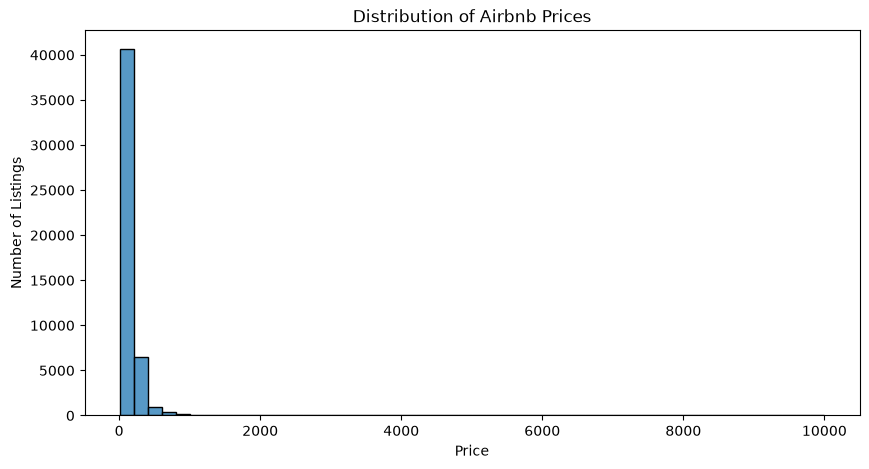

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(df_clean['price'], bins=50)

plt.title('Distribution of Airbnb Prices')
plt.xlabel('Price')
plt.ylabel('Number of Listings')

plt.show()

The histogram shows the distribution of Airbnb listing prices. I noticed that most listings are concentrated in the lower price range, while only a small number of listings have very high prices. The distribution is right-skewed because a few expensive properties extend the price range towards the right. This also explains why the average price is higher than the median price.

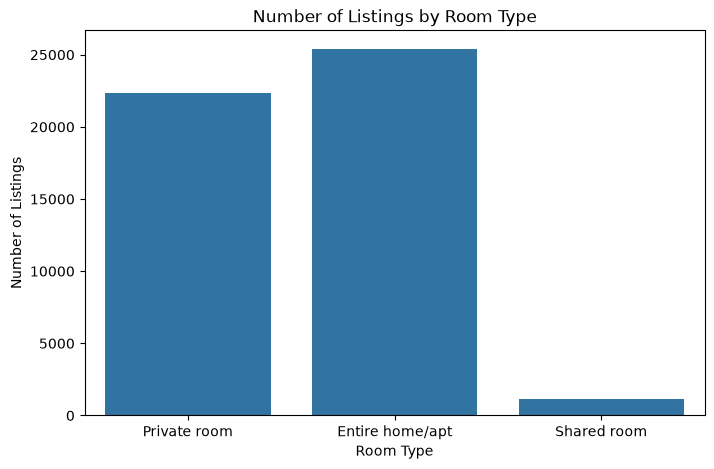

In [54]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='room_type')

plt.title('Number of Listings by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Number of Listings')

plt.show()

The bar chart shows the number of listings in each room type. I found that entire homes or apartments have the highest number of listings, with 25,407 properties. Private rooms are also common, with 22,319 listings. Shared rooms have the lowest number, with only 1,158 listings. This shows that entire homes and private rooms make up most of the Airbnb listings in the dataset.

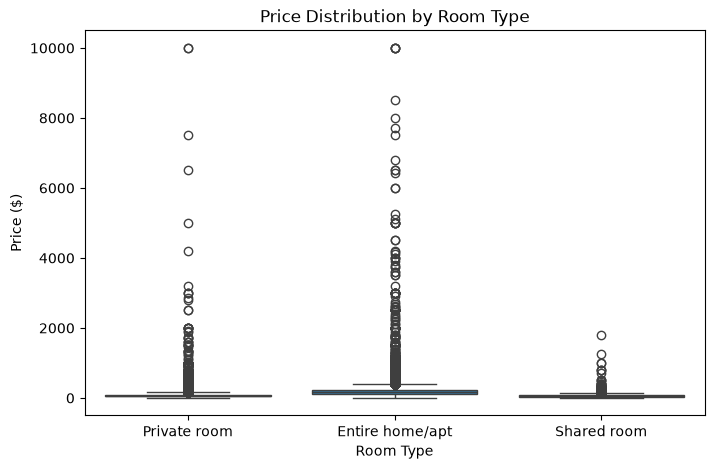

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='room_type', y='price')
plt.title('Price Distribution by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')
plt.show()

The box plot compares the prices of different room types. I noticed that entire homes or apartments have the highest median price, while shared rooms have the lowest. Private rooms fall between these two categories. The chart also shows several points above the upper whiskers, which represent potential outliers. Some listings have very high prices compared with most properties in their room category.